In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime, timedelta, timezone
from concurrent.futures import ThreadPoolExecutor, as_completed
from threading import Lock
import os
import joblib
import yfinance as yf
import traceback
import random

# ML & DL
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split, TimeSeriesSplit

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.saving import load_model as keras_load_model

# TA Lib & Sentiment
try:
    import pandas_ta as ta
except ImportError:
    print("Библиотека pandas_ta не найдена. Пожалуйста, установите ее: pip install pandas_ta")

try:
    from textblob import TextBlob
except ImportError:
    print("Библиотека textblob не найдена. Sentiment analysis будет отключен (0.0). pip install textblob")
    TextBlob = None

from IPython.display import display
import warnings

warnings.filterwarnings("ignore")


Библиотека textblob не найдена. Sentiment analysis будет отключен (0.0). pip install textblob


In [50]:
# --- ГЛОБАЛЬНЫЕ ПАРАМЕТРЫ ---

INSTRUMENT_TICKER = "AAPL"
FEATURE_COLUMN = 'close'
Z_SCORE_THRESHOLD = 4.0
N_CV_SPLITS = 4  # Фолды Walk-Forward
NUM_CANDIDATES = 4  # Сколько моделей обучать для каждого таймфрейма (выбор лучшей)
MAX_CV_WORKERS = min(N_CV_SPLITS, (os.cpu_count() or 1) * 2)
TEST_SPLIT_SIZE = 0.10
RANDOM_STATE = 42

# Директории
OUTPUT_CSV_DIRECTORY = "future_predictions_pro"
MODEL_SAVE_DIR = "trained_models_pro"

# TA Config
SMA_PERIODS = [10, 20, 50, 200]
MACD_FAST = 12
MACD_SLOW = 26
MACD_SIGNAL = 9
ATR_PERIOD = 14
BBANDS_PERIOD = 20
BBANDS_STD_DEV = 2
RSI_PERIOD = 14
STOCH_K = 14
STOCH_D = 3
STOCH_SMOOTH_K = 3

print_lock = Lock()
MAX_GAP_MULTIPLIER_FOR_PLOT = 5.0

# GPU Setup
gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)



In [51]:
# --- БЛОК 0: Логирование и Утилиты (Rich Output) ---

def log_step(model_name, message):
    with print_lock:
        print(f"[{model_name.strip('_')}] {message}")


def log_detailed(model_name, stage_name, data=None, details=""):
    """Выводит детальную информацию и таблицы (для Jupyter)."""
    prefix = f"[{model_name.strip('_')}][{stage_name}]"
    with print_lock:
        print(f"\n{'=' * 10} {prefix} ЗАПУСК {'=' * 10}")
        print(f">> {details}")

        if data is not None:
            if isinstance(data, pd.DataFrame):
                print(f">> DataFrame Info: Shape={data.shape}")
                if not data.empty:
                    print(f"   Range: {data.index.min()} ... {data.index.max()}")
                    # Красивый вывод таблицы
                    print(f"   Пример данных (Head & Tail):")
                    display(pd.concat([data.head(3), data.tail(3)]))
                    print(f"   Stats ({FEATURE_COLUMN}):")
                    if FEATURE_COLUMN in data.columns:
                        display(data[[FEATURE_COLUMN]].describe().T)
            elif isinstance(data, np.ndarray):
                print(f">> Array Info: Shape={data.shape}")

        print(f"{'=' * 10} {prefix} ЗАВЕРШЕНО {'=' * 10}\n")


def get_timedelta_from_candle_interval(interval_str: str) -> timedelta:
    mapping = {
        '1m': timedelta(minutes=1), '2m': timedelta(minutes=2), '5m': timedelta(minutes=5),
        '15m': timedelta(minutes=15), '30m': timedelta(minutes=30), '60m': timedelta(minutes=60),
        '1h': timedelta(hours=1), '90m': timedelta(minutes=90),
        '1d': timedelta(days=1), '5d': timedelta(days=5), '1wk': timedelta(weeks=1), '1mo': timedelta(days=30)
    }
    return mapping.get(interval_str, timedelta(minutes=1))


def generate_plotted_times_and_values(real_timestamps, values, timeframe_td,
                                      max_gap_multiplier=MAX_GAP_MULTIPLIER_FOR_PLOT):
    if len(real_timestamps) == 0 or len(values) == 0: return np.array([]), np.array([])
    try:
        real_ts = pd.DatetimeIndex(pd.to_datetime(real_timestamps))
        values_np = np.asarray(values)
        plotted_ts = [real_ts[0]]

        for i in range(1, len(real_ts)):
            diff = real_ts[i] - real_ts[i - 1]
            last = plotted_ts[-1]
            if diff > timeframe_td * max_gap_multiplier:
                plotted_ts.append(last + timeframe_td)
            else:
                plotted_ts.append(last + diff)
        return np.array(plotted_ts), values_np
    except:
        return np.array(pd.to_datetime(real_timestamps)), np.asarray(values)


def save_predictions_to_csv(df, model_name, ticker, target, interval, output_dir=OUTPUT_CSV_DIRECTORY):
    if df is None or df.empty: return
    try:
        os.makedirs(output_dir, exist_ok=True)
        ts = datetime.now().strftime("%Y%m%d_%H%M%S")
        filename = f"pred_{ticker}_{model_name}_{ts}.csv"
        filepath = os.path.join(output_dir, filename)

        df_save = df.copy().reset_index()
        df_save.rename(columns={'datetime': 'future_timestamp', 'predicted_value': f'predicted_price'}, inplace=True)
        df_save['model'] = model_name
        df_save.to_csv(filepath, index=False)
        log_step(model_name, f"Saved CSV: {filepath}")
    except Exception as e:
        log_step(model_name, f"CSV Error: {e}")


# --- БЛОК 1: Оркестрация ---

def check_bundle_exists(model_name, base_dir=MODEL_SAVE_DIR):
    path = os.path.join(base_dir, model_name)
    if not os.path.isdir(path): return False
    files = ["model.keras", "scaler_X.joblib", "scaler_y.joblib", "metadata.joblib", "df_history.pkl"]
    return all(os.path.exists(os.path.join(path, f)) for f in files)


def check_all_bundles_exist(model_configs_list, base_dir=MODEL_SAVE_DIR):
    if not model_configs_list: return False
    for config in model_configs_list:
        if not check_bundle_exists(config["name"], base_dir): return False
    return True


def save_model_bundle(model, sX, sY, features, df_hist, interval_td, n_in, n_out, name, base_dir=MODEL_SAVE_DIR):
    try:
        path = os.path.join(base_dir, name)
        os.makedirs(path, exist_ok=True)
        model.save(os.path.join(path, "model.keras"))
        joblib.dump(sX, os.path.join(path, "scaler_X.joblib"))
        joblib.dump(sY, os.path.join(path, "scaler_y.joblib"))
        meta = {"features": features, "interval_sec": interval_td.total_seconds(), "n_in": n_in, "n_out": n_out}
        joblib.dump(meta, os.path.join(path, "metadata.joblib"))
        df_hist.to_pickle(os.path.join(path, "df_history.pkl"))
        log_step(name, "Bundle Saved Successfully.")
        return True
    except Exception as e:
        log_step(name, f"Bundle Save Error: {e}")
        return False


def load_model_bundle(name, base_dir=MODEL_SAVE_DIR):
    path = os.path.join(base_dir, name)
    try:
        if not check_bundle_exists(name, base_dir): return None
        model = keras_load_model(os.path.join(path, "model.keras"), compile=True)
        sX = joblib.load(os.path.join(path, "scaler_X.joblib"))
        sY = joblib.load(os.path.join(path, "scaler_y.joblib"))
        meta = joblib.load(os.path.join(path, "metadata.joblib"))
        df_h = pd.read_pickle(os.path.join(path, "df_history.pkl"))
        if df_h.index.tz is not None: df_h.index = df_h.index.tz_convert('UTC').tz_localize(None)
        log_detailed(name, "BUNDLE LOADED", df_h, "История загружена из файла.")
        return {"model": model, "scaler_X": sX, "scaler_y": sY, "metadata": meta, "df_history": df_h}
    except Exception as e:
        return None


# --- БЛОК 2: Данные и TA (Stationary) ---

def get_news_sentiment(ticker):
    if TextBlob is None: return 0.0
    try:
        tick = yf.Ticker(ticker)
        news = tick.news
        if not news: return 0.0
        scores = [TextBlob(f"{n.get('title', '')} {n.get('summary', '')}").sentiment.polarity for n in news]
        return sum(scores) / len(scores) if scores else 0.0
    except:
        return 0.0


def get_market_data(ticker, days, interval, model_name=""):
    try:
        start = datetime.now() - timedelta(days=days)
        df = yf.download(ticker, start=start, interval=interval, progress=False, threads=True)
        if df.empty: return pd.DataFrame()
        if isinstance(df.columns, pd.MultiIndex): df.columns = df.columns.droplevel(1)
        df.columns = df.columns.str.lower()
        df.index.name = 'time'
        if df.index.tz is not None: df.index = df.index.tz_convert('UTC').tz_localize(None)
        df = df[['open', 'high', 'low', 'close', 'volume']].dropna().sort_index()
        log_detailed(model_name, "DATA FETCH", df, f"Downloaded for {interval}")
        return df
    except:
        return pd.DataFrame()


def add_technical_indicators_stationary(df, model_name="", is_future=False):
    if df.empty: return df
    df_ta = df.copy()
    df_ta = df_ta.loc[:, ~df_ta.columns.duplicated()]

    # Target: Log Return
    df_ta['log_ret'] = np.log(df_ta['close'] / df_ta['close'].shift(1))

    try:
        for p in SMA_PERIODS:
            sma = ta.sma(df_ta['close'], length=p)
            df_ta[f'dist_sma_{p}'] = (df_ta['close'] - sma) / sma

        df_ta['rsi'] = ta.rsi(df_ta['close'], length=RSI_PERIOD)

        macd = ta.macd(df_ta['close'], fast=MACD_FAST, slow=MACD_SLOW, signal=MACD_SIGNAL)
        if macd is not None:
            df_ta['macd_norm'] = macd.iloc[:, 0] / df_ta['close']
            df_ta['macd_sig_norm'] = macd.iloc[:, 1] / df_ta['close']
            df_ta['macd_hist_norm'] = macd.iloc[:, 2] / df_ta['close']

        stoch = ta.stoch(df_ta['high'], df_ta['low'], df_ta['close'], k=STOCH_K, d=STOCH_D)
        if stoch is not None: df_ta = pd.concat([df_ta, stoch], axis=1)

        atr = ta.atr(df_ta['high'], df_ta['low'], df_ta['close'], length=ATR_PERIOD)
        if atr is not None: df_ta['atr_pct'] = atr / df_ta['close']

        df_ta['vol_chg'] = df_ta['volume'].pct_change().replace([np.inf, -np.inf], 0)

        rsi_fill = df_ta['rsi'].fillna(50)
        tech_sent = (rsi_fill - 50) / 50.0
        df_ta['sentiment'] = tech_sent
        if not is_future and not df_ta.empty:
            real = get_news_sentiment(INSTRUMENT_TICKER)
            if real != 0.0:
                df_ta.iloc[-1, df_ta.columns.get_loc('sentiment')] = (tech_sent.iloc[-1] * 0.7) + (real * 0.3)

        df_ta = df_ta.loc[:, ~df_ta.columns.duplicated()]
        return df_ta
    except:
        return df


def remove_outliers_zscore(df, col, thresh, model_name):
    if col not in df.columns: return df
    try:
        mean = df[col].mean()
        std = df[col].std()
        if std == 0: return df
        z = (df[col] - mean) / std
        mask = np.abs(z) <= thresh
        return df[mask]
    except:
        return df


# --- БЛОК 3: Preprocessing & Sequencing ---

def prepare_dataframe(ticker, days, interval, col, thresh, model_name, tf_td):
    log_step(model_name, "Загрузка и предобработка данных...")
    df = get_market_data(ticker, days, interval, model_name)
    if df.empty: return None, None

    df_raw = df.copy()
    df_clean = remove_outliers_zscore(df, col, thresh, model_name)

    log_detailed(model_name, "OUTLIER REMOVAL", df_clean, f"Удалено {len(df_raw) - len(df_clean)} строк.")

    df_final = add_technical_indicators_stationary(df_clean, model_name)
    df_final = df_final.dropna()

    log_detailed(model_name, "FEATURES ADDED", df_final, "Готово к скейлингу.")
    return df_final, (df_raw, df_clean)


def get_stationary_feature_names(df_columns):
    exclude = ['open', 'high', 'low', 'close', 'volume', 'adj close', 'log_ret']
    return [c for c in df_columns if c not in exclude]


def create_sequences(X_data, y_data, prices_for_reconstruction, n_in, n_out, timestamps):
    X, y, t, base_prices = [], [], [], []
    if len(X_data) < n_in + n_out: return np.array(X), np.array(y), np.array(t), np.array(base_prices)
    for i in range(len(X_data) - n_in - n_out + 1):
        X.append(X_data[i: i + n_in])
        y.append(y_data[i + n_in: i + n_in + n_out])
        t.append(timestamps[i + n_in])
        base_prices.append(prices_for_reconstruction[i + n_in - 1])
    return np.array(X), np.array(y), np.array(t), np.array(base_prices)


# --- БЛОК 4: Модель и Обучение (Tournament) ---

def build_lstm(n_in, n_out, n_feat):
    m = Sequential([
        LSTM(128, return_sequences=True, input_shape=(n_in, n_feat)),
        BatchNormalization(), Dropout(0.2),
        LSTM(128, return_sequences=True),
        BatchNormalization(), Dropout(0.2),
        LSTM(64, return_sequences=False),
        BatchNormalization(), Dropout(0.2),
        Dense(32, activation='relu'),
        Dense(n_out)
    ])
    m.compile(optimizer=Adam(learning_rate=0.0005), loss='mse', metrics=['mae'])
    return m


def calculate_metrics(y_true, y_pred):
    if len(y_true) == 0: return {}
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    mean_y = np.mean(y_true)
    mae_pct = (mae / abs(mean_y)) * 100 if mean_y != 0 else 0
    return {'mse': mse, 'rmse': rmse, 'mae': mae, 'r2': r2, 'mae_pct': mae_pct}


def run_walk_forward_cv(X, y, n_in, n_out, n_feat, name, candidate_id):
    """Обучает одну модель-кандидата."""
    tscv = TimeSeriesSplit(n_splits=N_CV_SPLITS)
    best_model = None
    best_r2 = -float('inf')

    # Для каждого кандидата проходим Walk-Forward
    for fold, (train_idx, val_idx) in enumerate(tscv.split(X)):
        X_t, X_v = X[train_idx], X[val_idx]
        y_t, y_v = y[train_idx], y[val_idx]

        model = build_lstm(n_in, n_out, n_feat)
        es = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
        rlr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3)

        model.fit(X_t, y_t, validation_data=(X_v, y_v), epochs=40, batch_size=32, verbose=0, callbacks=[es, rlr])

        preds = model.predict(X_v, verbose=0)
        r2 = r2_score(y_v[:, 0], preds[:, 0])  # Score on 1st step log returns

        if r2 > best_r2:
            best_r2 = r2
            best_model = model

    return best_model, best_r2


def prepare_evaluation_data(model, X, y, base_prices, timestamps, scaler_y, tag="Test"):
    try:
        preds_scaled = model.predict(X, verbose=0)
        preds_flat = scaler_y.inverse_transform(preds_scaled.reshape(-1, 1)).flatten()
        preds_ret = preds_flat.reshape(preds_scaled.shape)

        y_flat = scaler_y.inverse_transform(y.reshape(-1, 1)).flatten()
        y_ret = y_flat.reshape(y.shape)

        pred_prices = base_prices * np.exp(preds_ret[:, 0])
        actual_prices = base_prices * np.exp(y_ret[:, 0])

        metrics = calculate_metrics(actual_prices, pred_prices)
        return {"type": tag, "timestamps": timestamps, "actual": actual_prices, "predicted": pred_prices,
                "metrics": metrics}
    except:
        return None


# --- БЛОК 5: Прогноз Будущего ---

def predict_future_recursive(model, sX, sY, df_hist, stationary_feats, n_fut, n_in, n_out, tf_td, name):
    log_step(name, f"Generating recursive forecast ({n_fut} steps) with Stochastic Noise...")
    hist = df_hist.copy().loc[:, ~df_hist.columns.duplicated()]
    
    future_prices = []
    future_dates = []
    last_dt = hist.index[-1]
    
    # --- ВАЖНО: Определяем волатильность последних свечей для реалистичности ---
    # Берем последние 50 лог-доходностей, чтобы понять текущий "размах" рынка
    recent_returns = np.diff(np.log(hist['close'].tail(51).values))
    # Если данных мало, берем дефолтное маленькое значение
    base_volatility = np.std(recent_returns) if len(recent_returns) > 1 else 0.001
    
    steps_done = 0
    while steps_done < n_fut:
        # Подготовка окна данных
        input_df = hist[stationary_feats].iloc[-n_in:].fillna(method='ffill').fillna(method='bfill')
        
        # Защита от пустот, если история вдруг короче n_in
        if len(input_df) < n_in:
             # Дополняем копиями первой строки, если не хватает
             pad = pd.DataFrame([input_df.iloc[0]] * (n_in - len(input_df)), columns=input_df.columns)
             input_df = pd.concat([pad, input_df], ignore_index=True)

        X_val = sX.transform(input_df.values).reshape(1, n_in, -1)
        
        # 1. "Чистый" прогноз модели (стремится к нулю/среднему)
        pred_scaled = model.predict(X_val, verbose=0)
        pred_ret = sY.inverse_transform(pred_scaled).flatten()
        
        # 2. ДОБАВЛЕНИЕ ШУМА (STOCHASTIC INJECTION)
        # Это оживляет график. Мы добавляем шум пропорционально текущей волатильности.
        # factor=0.8 немного сглаживает шум, чтобы не было слишком резких скачков
        noise = np.random.normal(0, base_volatility, size=pred_ret.shape) * 0.8
        pred_ret_noisy = pred_ret + noise
        
        last_known_price = hist['close'].iloc[-1]
        
        # Используем предсказание с шумом для расчета цены
        cum_ret = np.cumsum(pred_ret_noisy)
        chunk_prices = last_known_price * np.exp(cum_ret)
        
        chunk_len = min(len(chunk_prices), n_fut - steps_done)
        chunk_prices = chunk_prices[:chunk_len]
        
        new_rows = []
        for p in chunk_prices:
            last_dt += tf_td
            row = {c: np.nan for c in hist.columns}
            # Заполняем основные колонки ценой
            row['open'] = p; row['high'] = p; row['low'] = p; row['close'] = p
            # Объем копируем последний, либо можно добавить случайную вариацию
            if 'volume' in hist.columns: 
                row['volume'] = hist['volume'].iloc[-1]
            new_rows.append(pd.DataFrame([row], index=[last_dt]))
            
        temp_df = pd.concat(new_rows)
        temp_df = temp_df.loc[:, ~temp_df.columns.duplicated()]
        
        # Добавляем в историю для следующего шага
        hist = pd.concat([hist, temp_df])
        hist = hist.loc[:, ~hist.columns.duplicated()]
        
        # Пересчитываем индикаторы только для "хвоста" (+ запас для оконных функций)
        # Это важно, чтобы RSI/MACD реагировали на новые цены
        tail_len = n_in + 100 
        tail = hist.iloc[-tail_len:].copy()
        
        # Флаг is_future=True добавляем, чтобы (если есть логика новостей) она не ломалась
        tail_ta = add_technical_indicators_stationary(tail, name, is_future=True)
        
        # Аккуратно обновляем значения в основном датафрейме
        common_idx = tail_ta.index
        for col in stationary_feats:
            if col in hist.columns and col in tail_ta.columns:
                hist.loc[common_idx, col] = tail_ta.loc[common_idx, col]
        
        future_prices.extend(chunk_prices)
        future_dates.extend(temp_df.index)
        steps_done += chunk_len
        
        # Обновляем волатильность для следующего шага (адаптивность)
        # Если прогноз начал "скакать", следующая волатильность тоже подстроится
        new_recent_ret = np.diff(np.log(hist['close'].tail(30).values))
        if len(new_recent_ret) > 5:
            base_volatility = np.std(new_recent_ret)

    return pd.DataFrame({'datetime': future_dates, 'predicted_value': future_prices}).set_index('datetime')

# --- БЛОК 6: MAIN PIPELINE ---

def run_pipeline(cfg, loaded_bundle=None):
    name = cfg['name']
    interval = cfg['candle_timeframe']
    days = cfg['days_history']
    n_in = cfg['n_steps_in']
    n_out = cfg['n_steps_out']
    n_fut = cfg['future_predictions']
    tf_td = get_timedelta_from_candle_interval(interval)

    result_pkg = {
        'name': name, 'interval_td': tf_td,
        'outliers_data': None, 'train_eval_data': None,
        'test_eval_data': None, 'future_df': None, 'context_history': None
    }

    try:
        if loaded_bundle:
            log_step(name, "Режим ЗАГРУЗКИ. Обновление данных...")
            model = loaded_bundle['model']
            sX = loaded_bundle['scaler_X']
            sY = loaded_bundle['scaler_y']
            feats = loaded_bundle['metadata']['features']
            df_h = loaded_bundle['df_history']

            last_ts = df_h.index[-1]
            now = datetime.now().replace(tzinfo=None)
            if df_h.index.tz is not None: df_h.index = df_h.index.tz_convert('UTC').tz_localize(None)

            delta = (now - last_ts).days + 2
            if delta > 0:
                df_new = get_market_data(INSTRUMENT_TICKER, delta, interval, f"{name}-Upd")
                if not df_new.empty:
                    df_new = df_new[df_new.index > last_ts]
                    if not df_new.empty:
                        common = ['open', 'high', 'low', 'close', 'volume']
                        df_combined = pd.concat([df_h[common], df_new[common]]).sort_index()
                        df_combined = df_combined.loc[:, ~df_combined.columns.duplicated()]
                        df_combined = df_combined[~df_combined.index.duplicated(keep='last')]
                        df_h = add_technical_indicators_stationary(df_combined, name)
                        df_h = df_h.dropna()
                        log_step(name, f"Данные обновлены. Новый конец: {df_h.index[-1]}")
        else:
            log_step(name, "Режим ОБУЧЕНИЯ (Tournament of 4 models)...")
            df_full, outliers_tuple = prepare_dataframe(INSTRUMENT_TICKER, days, interval, FEATURE_COLUMN,
                                                        Z_SCORE_THRESHOLD, name, tf_td)
            if df_full is None: return None

            # --- ВАЖНО: Сохраняем данные для графика выбросов ---
            result_pkg['outliers_data'] = outliers_tuple
            stationary_feats = get_stationary_feature_names(df_full.columns)

            split_idx = int(len(df_full) * (1 - TEST_SPLIT_SIZE))
            df_train = df_full.iloc[:split_idx]
            df_test = df_full.iloc[split_idx - n_in:]

            sX = StandardScaler()
            sY = StandardScaler()
            sX.fit(df_train[stationary_feats].values)
            sY.fit(df_train[['log_ret']].values)

            X_tr, y_tr, t_tr, base_tr = create_sequences(
                sX.transform(df_train[stationary_feats].values),
                sY.transform(df_train[['log_ret']].values).flatten(),
                df_train['close'].values, n_in, n_out, df_train.index
            )

            X_te, y_te, t_te, base_te = create_sequences(
                sX.transform(df_test[stationary_feats].values),
                sY.transform(df_test[['log_ret']].values).flatten(),
                df_test['close'].values, n_in, n_out, df_test.index
            )

            # --- TOURNAMENT ---
            best_cand_model = None
            best_cand_score = -float('inf')

            log_step(name, f"Training {NUM_CANDIDATES} candidates sequentially...")

            for i in range(NUM_CANDIDATES):
                # Using random seed variation via loop (or explicit seed setting)
                # Keras builds fresh weights each call
                c_model, c_score = run_walk_forward_cv(X_tr, y_tr, n_in, n_out, len(stationary_feats), name, i)
                log_step(name, f"Candidate {i + 1} Score (R2): {c_score:.4f}")

                if c_score > best_cand_score:
                    best_cand_score = c_score
                    best_cand_model = c_model

            log_detailed(name, "WINNER SELECTED", details=f"Best R2: {best_cand_score:.4f}")
            model = best_cand_model

            if model:
                result_pkg['train_eval_data'] = prepare_evaluation_data(model, X_tr, y_tr, base_tr, t_tr, sY, "Train")
                result_pkg['test_eval_data'] = prepare_evaluation_data(model, X_te, y_te, base_te, t_te, sY, "Test")

                sX_full = StandardScaler().fit(df_full[stationary_feats].values)
                sY_full = StandardScaler().fit(df_full[['log_ret']].values)
                save_model_bundle(model, sX_full, sY_full, stationary_feats, df_full, tf_td, n_in, n_out, name)

                sX, sY = sX_full, sY_full
                feats = stationary_feats
                df_h = df_full

        if model and df_h is not None:
            result_pkg['context_history'] = df_h.iloc[-100:].copy()
            last_n_df = df_h[feats].iloc[-n_in:]
            init_x = sX.transform(last_n_df.values)
            fut_df = predict_future_recursive(model, sX, sY, df_h, feats, n_fut, n_in, n_out, tf_td, name)
            save_predictions_to_csv(fut_df, name, INSTRUMENT_TICKER, FEATURE_COLUMN, interval)
            result_pkg['future_df'] = fut_df

            return result_pkg

    except Exception as e:
        log_step(name, f"PIPELINE CRASH: {e}")
        traceback.print_exc()
        return None


# --- PLOTTING (Main Thread) ---

# --- ФУНКЦИЯ ПОСТРОЕНИЯ ГРАФИКА ВЫБРОСОВ ---
def plot_outliers_safe(data, name, tf_td):
    """
    Рисует график изначальных данных (с подсветкой выбросов)
    и график данных после очистки.
    """
    raw, clean = data
    if raw.empty: return
    try:
        plt.figure(figsize=(15, 8))

        # Subplot 1: Raw Data + Outliers
        ax1 = plt.subplot(2, 1, 1)
        pt, pv = generate_plotted_times_and_values(raw.index, raw[FEATURE_COLUMN], tf_td)
        if len(pt) > 0:
            ax1.plot(pt, pv, label='Исходные данные', color='#1f77b4')

            # Recalculate z-score to identify points to highlight
            mean, std = raw[FEATURE_COLUMN].mean(), raw[FEATURE_COLUMN].std()
            mask = np.abs((raw[FEATURE_COLUMN] - mean) / std) > Z_SCORE_THRESHOLD
            out_idx = raw[mask].index

            # Map indices to plotted times
            comm = raw.index.intersection(out_idx)
            idxs = [raw.index.get_loc(i) for i in comm if raw.index.get_loc(i) < len(pt)]
            if idxs:
                ax1.scatter(pt[idxs], pv[idxs], color='red', s=30, label=f'Выбросы (Z > {Z_SCORE_THRESHOLD})', zorder=5)

        ax1.set_title(f"[{name}] Анализ выбросов: Исходные данные")
        ax1.legend();
        ax1.grid(True)
        ax1.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d %H:%M'))

        # Subplot 2: Clean Data
        ax2 = plt.subplot(2, 1, 2)
        ptc, pvc = generate_plotted_times_and_values(clean.index, clean[FEATURE_COLUMN], tf_td)
        if len(ptc) > 0:
            ax2.plot(ptc, pvc, label='Очищенные данные', color='green')

        ax2.set_title(f"[{name}] Обработка: Данные после удаления выбросов")
        ax2.legend();
        ax2.grid(True)
        ax2.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d %H:%M'))

        plt.tight_layout()
        plt.show()
    except Exception as e:
        print(f"Plot Error: {e}")


def plot_evaluation_results(data, name, tf_td):
    if not data: return
    try:
        ts = data['timestamps']
        act = data['actual']
        pred = data['predicted']
        met = data['metrics']
        dtype = data['type']

        plt.figure(figsize=(15, 6))
        pt_a, pv_a = generate_plotted_times_and_values(ts, act, tf_td)
        pt_p, pv_p = generate_plotted_times_and_values(ts, pred, tf_td)

        c_a = '#1f77b4' if dtype == "Test" else 'purple'
        c_p = '#ff7f0e' if dtype == "Test" else 'orange'

        if len(pt_a) > 0:
            plt.plot(pt_a, pv_a, label=f'Факт ({dtype})', color=c_a, alpha=0.8)
            plt.plot(pt_p, pv_p, label=f'Прогноз ({dtype})', color=c_p, linestyle='--')

        plt.title(f"[{name}] {dtype} Оценка | R2: {met.get('r2', 0):.4f}")
        plt.legend();
        plt.grid(True, alpha=0.3)

        info = "\n".join([f"{k.upper()}: {v:.4f}" for k, v in met.items() if pd.notna(v)])
        plt.gca().text(0.01, 0.95, info, transform=plt.gca().transAxes, va='top', bbox=dict(fc='white', alpha=0.8))
        plt.show()
    except:
        pass


def plot_stitched_forecast(history_df, future_df, name, tf_td):
    if history_df is None or future_df is None: return
    try:
        plt.figure(figsize=(15, 7))
        hist_vals = history_df['close'].values
        pt_h, pv_h = generate_plotted_times_and_values(history_df.index, hist_vals, tf_td)

        combined_vals = np.concatenate([hist_vals, future_df['predicted_value'].values])
        combined_ts = list(history_df.index) + list(future_df.index)
        pt_c, pv_c = generate_plotted_times_and_values(combined_ts, combined_vals, tf_td)

        split_idx = len(pt_h)
        plt.plot(pt_c[:split_idx], pv_c[:split_idx], label='История', color='gray')
        plt.plot(pt_c[split_idx - 1:], pv_c[split_idx - 1:], label='Прогноз', color='#00ff00', linestyle='--',
                 linewidth=2)

        plt.title(f"[{name}] Прогноз со склейкой")
        plt.legend();
        plt.grid(True, alpha=0.3)
        plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M\n%d/%m'))
        plt.show()
    except:
        pass




========== [Model_1min_TF][BUNDLE LOADED] ЗАПУСК ==========
>> История загружена из файла.
>> DataFrame Info: Shape=(1736, 19)
   Range: 2025-12-01 17:49:00 ... 2025-12-05 20:59:00
   Пример данных (Head & Tail):


,open,high,low,close,volume,log_ret,dist_sma_10,dist_sma_20,dist_sma_50,dist_sma_200,rsi,macd_norm,macd_sig_norm,macd_hist_norm,STOCHk_14_3_3,STOCHd_14_3_3,atr_pct,vol_chg,sentiment
time,,,,,,,,,,,,,,,,,,,
2025-12-01 17:49:00,279.820007,279.829987,279.750000,279.750000,22283,-0.000250,0.000106,0.000282,0.001081,0.005370,60.097204,0.000370,-0.000006,0.000376,67.383322,71.230804,0.000433,-0.287992,0.201944
2025-12-01 17:50:00,279.750000,279.890015,279.725006,279.746796,37627,-0.000011,0.000032,0.000261,0.001019,0.005333,59.817759,0.000349,-0.000021,0.000371,63.527981,67.547740,0.000445,0.688597,0.196355
2025-12-01 17:51:00,279.750000,279.880005,279.709991,279.839996,26190,0.000333,0.000265,0.000554,0.001297,0.005636,64.926202,0.000356,-0.000012,0.000368,64.976775,65.296026,0.000456,-0.303957,0.298524
2025-12-05 20:57:00,278.304993,278.619995,278.279999,278.559998,145721,0.000898,0.000203,-0.000455,-0.000697,-0.001560,46.259374,-0.000384,-0.000107,-0.000277,23.554878,22.283813,0.000744,0.230481,-0.074813
2025-12-05 20:58:00,278.549988,278.619995,278.529999,278.579987,280018,0.000072,0.000242,-0.000311,-0.000616,-0.001490,47.039738,-0.000347,-0.000056,-0.000291,38.094672,24.753357,0.000713,0.921604,-0.059205
2025-12-05 20:59:00,278.589996,278.894989,278.587494,278.790009,629941,0.000754,0.000914,0.000467,0.000130,-0.000740,54.513441,-0.000254,0.000030,-0.000283,60.678017,40.775856,0.000743,1.249645,0.090269


   Stats (close):


,count,mean,std,min,25%,50%,75%,max
close,1736.0,282.615502,2.965109,278.065002,279.970001,281.617493,285.648872,288.26001


========== [Model_1min_TF][BUNDLE LOADED] ЗАВЕРШЕНО ==========


========== [Model_5min_TF][BUNDLE LOADED] ЗАПУСК ==========
>> История загружена из файла.
>> DataFrame Info: Shape=(1736, 19)
   Range: 2025-12-01 17:49:00 ... 2025-12-05 20:59:00
   Пример данных (Head & Tail):


,open,high,low,close,volume,log_ret,dist_sma_10,dist_sma_20,dist_sma_50,dist_sma_200,rsi,macd_norm,macd_sig_norm,macd_hist_norm,STOCHk_14_3_3,STOCHd_14_3_3,atr_pct,vol_chg,sentiment
time,,,,,,,,,,,,,,,,,,,
2025-12-01 17:49:00,279.820007,279.829987,279.750000,279.750000,22283,-0.000250,0.000106,0.000282,0.001081,0.005370,60.097204,0.000370,-0.000006,0.000376,67.383322,71.230804,0.000433,-0.287992,0.201944
2025-12-01 17:50:00,279.750000,279.890015,279.725006,279.746796,37627,-0.000011,0.000032,0.000261,0.001019,0.005333,59.817759,0.000349,-0.000021,0.000371,63.527981,67.547740,0.000445,0.688597,0.196355
2025-12-01 17:51:00,279.750000,279.880005,279.709991,279.839996,26190,0.000333,0.000265,0.000554,0.001297,0.005636,64.926202,0.000356,-0.000012,0.000368,64.976775,65.296026,0.000456,-0.303957,0.298524
2025-12-05 20:57:00,278.304993,278.619995,278.279999,278.559998,145721,0.000898,0.000203,-0.000455,-0.000697,-0.001560,46.259374,-0.000384,-0.000107,-0.000277,23.554878,22.283813,0.000744,0.230481,-0.074813
2025-12-05 20:58:00,278.549988,278.619995,278.529999,278.579987,280018,0.000072,0.000242,-0.000311,-0.000616,-0.001490,47.039738,-0.000347,-0.000056,-0.000291,38.094672,24.753357,0.000713,0.921604,-0.059205
2025-12-05 20:59:00,278.589996,278.894989,278.587494,278.790009,629941,0.000754,0.000914,0.000467,0.000130,-0.000740,54.513441,-0.000254,0.000030,-0.000283,60.678017,40.775856,0.000743,1.249645,0.090269


... (15 outputs left out)

Price,open,high,low,close,volume
time,,,,,
2025-12-04 14:30:00,284.109985,284.730011,283.790009,284.230011,1049218
2025-12-04 14:31:00,284.200012,284.649994,283.929993,283.941101,147137
2025-12-04 14:32:00,283.985992,284.029999,283.519989,283.809998,123325
2025-12-05 20:57:00,278.304993,278.619995,278.279999,278.559998,145721
2025-12-05 20:58:00,278.549988,278.619995,278.529999,278.579987,280018
2025-12-05 20:59:00,278.589996,278.894989,278.587494,278.790009,629941


   Stats (close):


,count,mean,std,min,25%,50%,75%,max
Price,,,,,,,,
close,772.0,279.868845,0.982296,278.065002,279.089996,279.919601,280.349251,284.230011


========== [Model_15min_TF-Upd][DATA FETCH] ЗАВЕРШЕНО ==========

[Model_1min_TF] Generating recursive forecast (30 steps) with Stochastic Noise...
[Model_5min_TF] Generating recursive forecast (60 steps) with Stochastic Noise...
[Model_15min_TF] Generating recursive forecast (24 steps) with Stochastic Noise...
[Model_1min_TF] Saved CSV: future_predictions_pro/pred_AAPL_Model_1min_TF_20251206_014619.csv
[Model_15min_TF] Saved CSV: future_predictions_pro/pred_AAPL_Model_15min_TF_20251206_014619.csv
[Model_5min_TF] Saved CSV: future_predictions_pro/pred_AAPL_Model_5min_TF_20251206_014619.csv

>>> ГЕНЕРАЦИЯ ГРАФИКОВ...


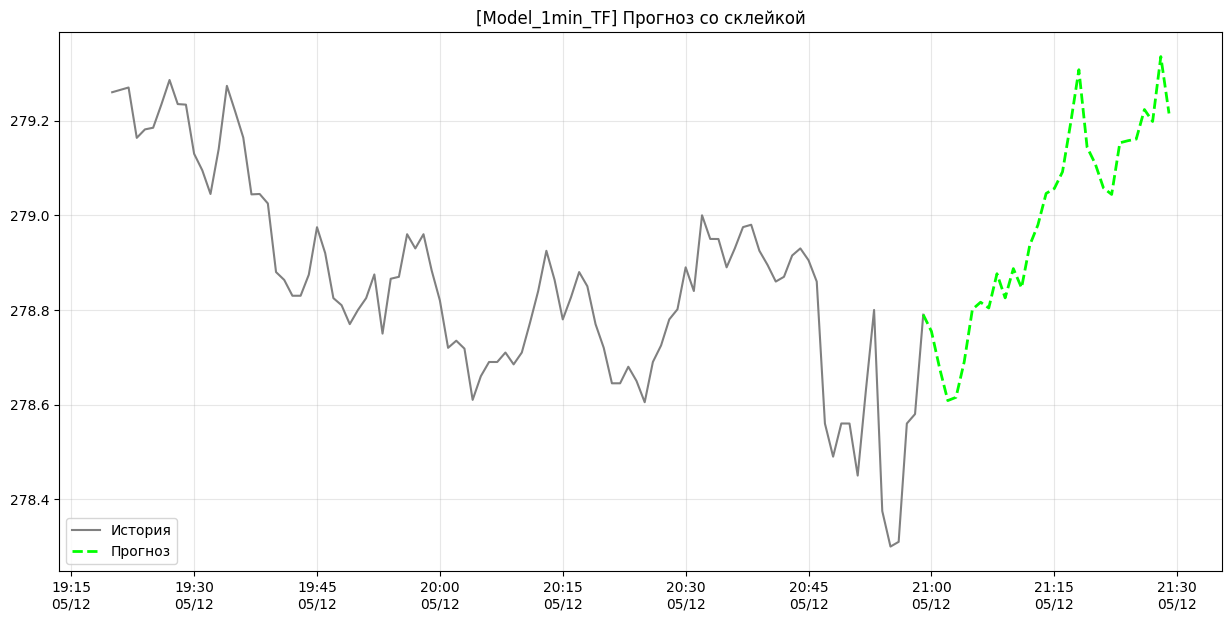

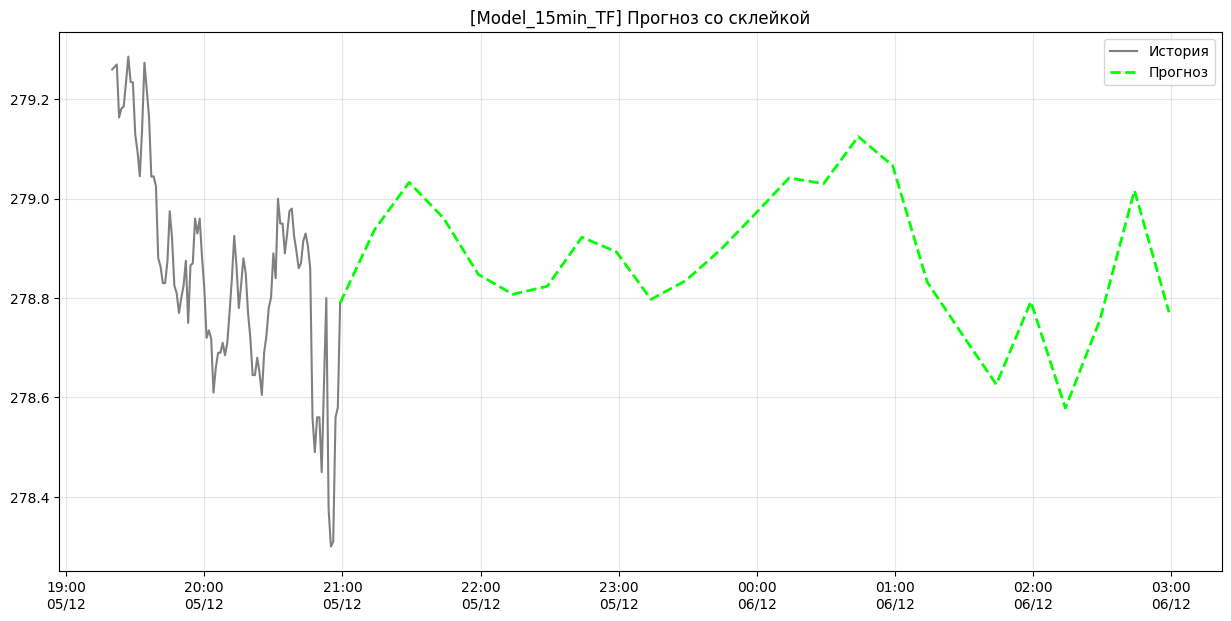

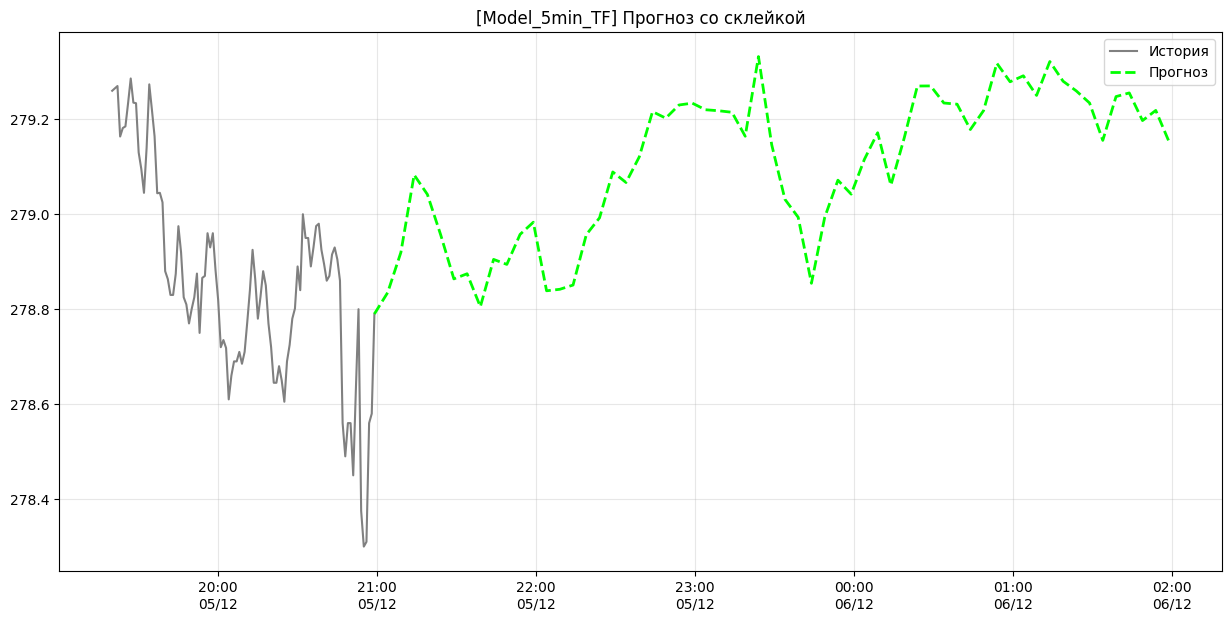

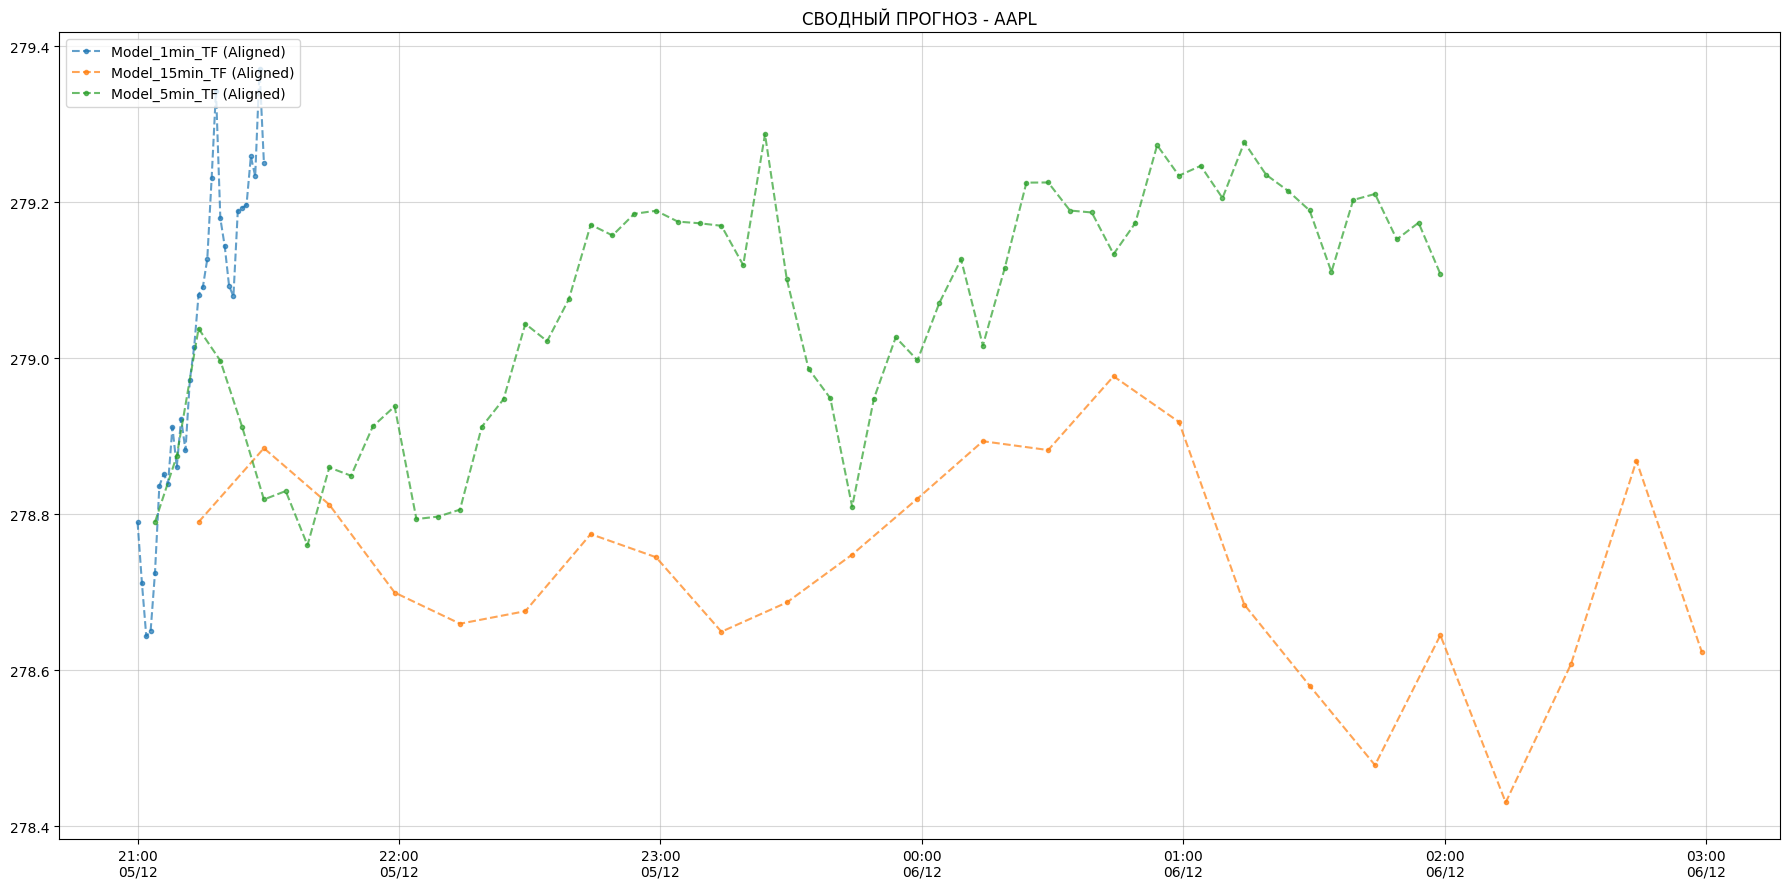


--- ГОТОВО ---


In [52]:
if __name__ == "__main__":
    configs = [
        {"name": "Model_1min_TF", "days_history": 7, "candle_timeframe": "1m", "n_steps_in": 150, "n_steps_out": 15,
         "future_predictions": 30},
        {"name": "Model_5min_TF", "days_history": 59, "candle_timeframe": "5m", "n_steps_in": 200, "n_steps_out": 20,
         "future_predictions": 60},
        {"name": "Model_15min_TF", "days_history": 59, "candle_timeframe": "15m", "n_steps_in": 100, "n_steps_out": 10,
         "future_predictions": 24}
    ]

    loaded_data = {}
    if check_all_bundles_exist(configs):
        if input("Загрузить существующие? (да/нет): ").lower() == 'да':
            for c in configs:
                b = load_model_bundle(c['name'])
                if b: loaded_data[c['name']] = b

    print("\n>>> ЗАПУСК ПОТОКОВ (Обучение / Прогноз)...")
    final_results = []

    with ThreadPoolExecutor(max_workers=min(len(configs), 3)) as ex:
        futs = {ex.submit(run_pipeline, c, loaded_data.get(c['name'])): c for c in configs}
        for f in as_completed(futs):
            r = f.result()
            if r: final_results.append(r)

    print("\n>>> ГЕНЕРАЦИЯ ГРАФИКОВ...")

    for res in final_results:
        name = res['name']
        tf = res['interval_td']

        # --- ВЫЗОВ ПОСТРОЕНИЯ ГРАФИКА ВЫБРОСОВ ---
        if res['outliers_data']:
            plot_outliers_safe(res['outliers_data'], name, tf)

        if res['train_eval_data']:
            plot_evaluation_results(res['train_eval_data'], name, tf)
        if res['test_eval_data']:
            plot_evaluation_results(res['test_eval_data'], name, tf)
        if res['future_df'] is not None and res['context_history'] is not None:
            plot_stitched_forecast(res['context_history'], res['future_df'], name, tf)

    if final_results:
        plt.figure(figsize=(18, 9))
        latest_price = 0
        for res in final_results:
            if res['context_history'] is not None:
                p = res['context_history'].iloc[-1]['close']
                if p > 0: latest_price = p  # Approximate anchor

        for res in final_results:
            if res['future_df'] is not None:
                df = res['future_df'].copy()
                if not df.empty and latest_price > 0:
                    start_p = df['predicted_value'].iloc[0]
                    # Simple alignment
                    df['predicted_value'] = df['predicted_value'] * (latest_price / start_p)

                    pt, pv = generate_plotted_times_and_values(df.index, df['predicted_value'].values,
                                                               res['interval_td'])
                    if len(pt) > 0:
                        plt.plot(pt, pv, label=f"{res['name']} (Aligned)", marker='.', linestyle='--', alpha=0.7)

        plt.title(f"СВОДНЫЙ ПРОГНОЗ - {INSTRUMENT_TICKER}")
        plt.legend(loc='upper left')
        plt.grid(True, alpha=0.5)
        plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M\n%d/%m'))
        plt.tight_layout()
        plt.show()

    print("\n--- ГОТОВО ---")